In [1]:
import sys,os
os.environ["JAX_PLATFORMS"] = "cpu"

import jax
jax.config.update("jax_enable_x64", True)

from datetime import datetime
now = datetime.now()
print(now.strftime("%Y-%m-%d %H:%M:%S"))

sys.path.append('../')
sys.path.append('../../')

from collections import defaultdict
import numpy as np

from geometry import *
from utils import (bf16_torch_to_jax, 
            flatten_tokens_features, 
            list_folder, 
            binarize, 
            clip,
            makefolder,
            depths,
            emb_dims,
            )
import pickle
from tqdm import tqdm
import torch
from datapaths import *
import argparse
from time import time
from ranks import collect_data
import matplotlib.pyplot as plt


2025-06-24 13:27:09
2025-06-24 13:27:11


In [2]:
input_path_A =  "/home/laios/activations/opus_english_spanish/deepseek/deepseek_english"
input_path_B =  "/home/laios/activations/opus_english_spanish/deepseek/deepseek_spanish"

all_activations_A = collect_data(input_path_A,
                                n_loaded_tokens=38, 
                                n_files=20,
                                mask=2,
                                )
all_activations_B = collect_data(input_path_B,
                                  n_loaded_tokens=38, 
                                  n_files=20,
                                  mask=2,
                                  )   

Collect File: 100%|██████████| 20/20 [00:11<00:00,  1.76it/s]


n_tokens=1
Nbits=1
avg_tokens=0
Nbits=0
avg_tokens=0


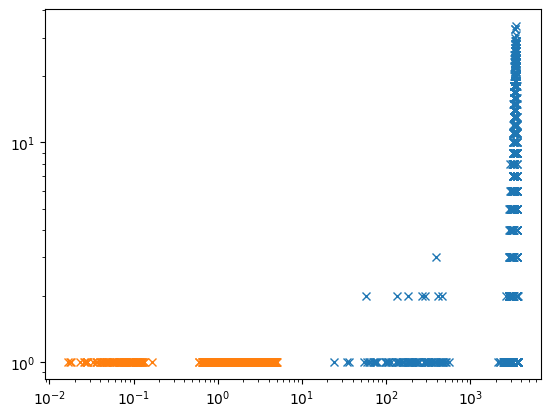

In [ ]:
n_tokens_list = np.array([1])
# k_list = [10] 
Nbits_list = [1,0]
avg_flags = [0]
diagonal_constraint = 1

total_sample_size = all_activations_A["layer_1"].shape[0]

layers_A = [1]
layers_B = [1]

key_distances = jax.random.key(42)
key_distances, subkey_distances = jax.random.split(key_distances) 

for n_tokens_id, n_tokens in enumerate(n_tokens_list):
    print(f'{n_tokens=}')
    for Nbits_id, Nbits in enumerate(Nbits_list):
        print(f'{Nbits=}')
        distance_fn = hamming_distance if Nbits else L2_distance 
        get_ranks = build_get_ranks(key=subkey_distances, 
                                    sample_size=total_sample_size, 
                                    distance_fn=distance_fn, 
                                    )
        
        for avg_tokens in avg_flags:
            print(f'{avg_tokens=}')

            for A_counter,layer_A in enumerate(layers_A):
                activations_A = all_activations_A[f"layer_{layer_A}"]

                for B_counter,layer_B in enumerate(layers_B):
                    activations_B = all_activations_B[f"layer_{layer_B}"]

                    if diagonal_constraint == 1 and layer_B != layer_A:
                        continue
                    act_A = bf16_torch_to_jax(activations_A[:,-n_tokens:,:])
                    act_B = bf16_torch_to_jax(activations_B[:,-n_tokens:,:])

                    act_A = flatten_tokens_features(act_A)
                    act_B = flatten_tokens_features(act_B)
                    
                    if Nbits == 1:
                        act_A = binarize(act_A)
                        act_B = binarize(act_B)

                    elif Nbits == 0:
                        act_A = clip(act_A,0.05,0.95).astype(jnp.double)
                        act_B = clip(act_B).astype(jnp.double)

                    
                    key = jax.random.PRNGKey(42)
                    indices_rows,indices_columns = separate_samples(key,total_sample_size)
                    d_X = pairwise_distances(distance_fn, act_A[indices_rows], act_A[indices_columns])
                    d_Y = pairwise_distances(distance_fn, act_B[indices_rows], act_B[indices_columns])

                    v,c= np.unique(d_X,return_counts=True)
                    plt.plot(v,c,'x')
plt.yscale('log')
plt.xscale('log')
plt.show()

n_tokens=1
Nbits=1
avg_tokens=0
Nbits=0
avg_tokens=0


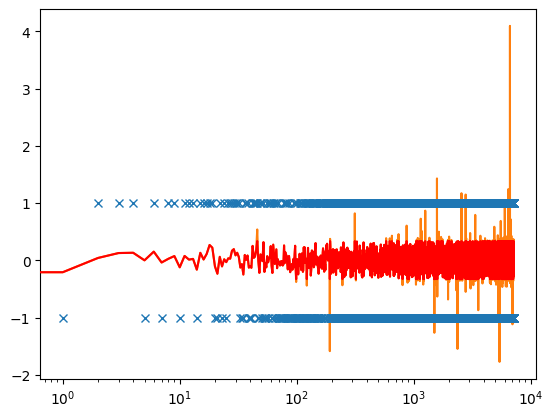

In [50]:
n_tokens_list = np.array([1])
# k_list = [10] 
Nbits_list = [1,0]
avg_flags = [0]
diagonal_constraint = 1

total_sample_size = all_activations_A["layer_1"].shape[0]

layers_A = [14]
layers_B = [14]

key_distances = jax.random.key(42)
key_distances, subkey_distances = jax.random.split(key_distances) 


fig,ax = plt.subplots(1)
# fig2,ax2 = plt.subplots(1)
for n_tokens_id, n_tokens in enumerate(n_tokens_list):
    print(f'{n_tokens=}')
    for Nbits_id, Nbits in enumerate(Nbits_list):
        print(f'{Nbits=}')
        distance_fn = hamming_distance if Nbits else normalized_L2_distance 
        get_ranks = build_get_ranks(key=subkey_distances, 
                                    sample_size=total_sample_size, 
                                    distance_fn=distance_fn, 
                                    )
        
        for avg_tokens in avg_flags:
            print(f'{avg_tokens=}')

            for A_counter,layer_A in enumerate(layers_A):
                activations_A = all_activations_A[f"layer_{layer_A}"]

                for B_counter,layer_B in enumerate(layers_B):
                    activations_B = all_activations_B[f"layer_{layer_B}"]

                    if diagonal_constraint == 1 and layer_B != layer_A:
                        continue

                    act_A = bf16_torch_to_jax(activations_A[:,-n_tokens:,:])
                    act_B = bf16_torch_to_jax(activations_B[:,-n_tokens:,:])

                    act_A = flatten_tokens_features(act_A)
                    act_B = flatten_tokens_features(act_B)

                    if Nbits == 1:
                        act_A = binarize(act_A)
                        act_B = binarize(act_B)
                        ax.plot(act_A[0],'x')

                    if Nbits == 0:
                        ax.plot(act_A[0],zorder=0) # with spikes
                        alphamin = 0.01
                        alphamax = 0.99
                        act_A = clip(act_A,alphamin,alphamax).astype(jnp.double)
                        act_B = clip(act_B,alphamin,alphamax).astype(jnp.double)
                        ax.plot(act_A[0],zorder=3,color='red') # without spikes
ax.set_xscale('log')
plt.show()

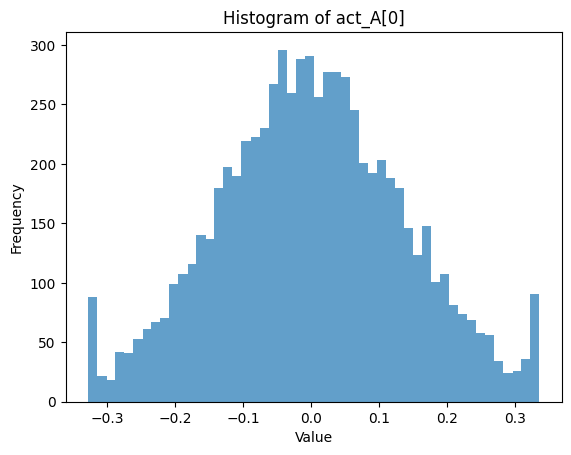

In [47]:
fig2,ax2 = plt.subplots(1)
ax2.hist(np.array(act_A[0]), bins=50, alpha=0.7)
ax2.set_title("Histogram of act_A[0]")
ax2.set_xlabel("Value")
ax2.set_ylabel("Frequency")
plt.show()

In [39]:
k = 0
n = 100
ds = np.zeros(shape=(n,))
hs = np.zeros(shape=ds.shape,dtype=int)
for l in range(1,n):
  ds[l] = normalized_L2_distance(act_A[k],act_A[l])
  hs[l] = hamming_distance(binarize(act_A)[k],binarize(act_A)[l])
  print(ds[l],hs[l])


1.3671875 3413
1.328125 3347
1.375 3521
1.3828125 3492
1.3671875 3429
1.34375 3383
1.3515625 3346
1.3515625 3398
1.34375 3351
1.3359375 3290
1.390625 3495
1.3125 3224
1.3984375 3545
1.3984375 3480
1.3671875 3437
1.3671875 3422
1.3828125 3453
1.3828125 3514
1.375 3421
1.3984375 3523
1.0078125 2433
1.375 3504
1.3671875 3434
1.3984375 3514
1.359375 3378
1.375 3484
1.3828125 3493
1.328125 3346
1.375 3474
1.359375 3401
1.359375 3388
1.375 3407
1.3671875 3389
1.3515625 3405
1.3671875 3447
1.375 3504
1.390625 3554
1.3203125 3304
1.359375 3404
1.3515625 3389
1.3828125 3470
1.3828125 3535
1.375 3473
1.375 3480
1.375 3512
1.3984375 3553
1.3203125 3283
1.3671875 3432
1.3828125 3533
1.359375 3402
1.3828125 3443
1.3671875 3396
1.3671875 3436
1.3671875 3408
1.359375 3429
1.34375 3411
1.3828125 3465
1.375 3408
1.3359375 3375
1.3515625 3360
1.3671875 3366
1.359375 3435
1.40625 3611
1.390625 3548
1.359375 3451
1.3828125 3468
1.375 3437
1.3828125 3472
1.3359375 3371
1.40625 3497
1.359375 3371
1.3984375 

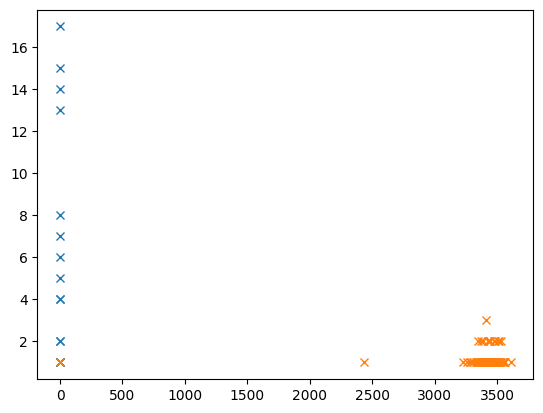

In [35]:
v,c= np.unique(ds,return_counts=True)
plt.plot(v,c,'x')
v,c= np.unique(hs,return_counts=True)
plt.plot(v,c,'x')

In [ ]:
"""1.3469129 3251
1.3235084 3139
1.3672674 3350
1.3337984 3188
1.3845046 3435
1.3721563 3374
1.4100643 3563
1.3367238 3202
1.3473272 3253
1.3794572 3410
1.3885293 3455
1.3887303 3456
1.390136 3463
1.3758116 3392
1.34981 3265
1.3788502 3407
1.399737 3511
1.3717495 3372
1.3863171 3444
1.4094707 3560"""